# 6주차. 1단계 통합 — TTM 적용, 전체 벤치마크, 배포 판단

In [1]:
import sys, os, json, subprocess, logging, re
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from src import bench_models as bm
from src.backtest import rolling_backtest
from src.metrics import compute_naive_denominators, score_backtest

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path("..").resolve()
OUT = ROOT / "results" / "wk6"
RAW = OUT / "raw_measure"
CACHE = OUT / "mase_cache"
for d in (RAW, CACHE):
    d.mkdir(parents=True, exist_ok=True)

N_THREADS = 4
torch.set_num_threads(N_THREADS)
N_WINDOWS, STEP_SIZE = 52, 168

data = bm.load_data()
weather, building_site = bm.load_weather(data)


def per_building_mase(res):
    denom = compute_naive_denominators(data, train_end=data.index.get_loc(res.timestamp.min()), season=168)
    return score_backtest(res, denom)[0].set_index("building")["MASE"]


def run_backtest(fns, horizon, **kw):
    mf, pf = fns
    return rolling_backtest(data, mf, pf, n_windows=N_WINDOWS, horizon=horizon, step_size=STEP_SIZE, **kw)


def cached_mase(tag, horizon, make_res):
    path = CACHE / f"{re.sub(r'[^0-9A-Za-z가-힣]+', '_', tag)}_{horizon}h.csv"
    if path.exists():
        return pd.read_csv(path, index_col=0)["MASE"]
    s = per_building_mase(make_res()).rename("MASE")
    s.to_csv(path, encoding="utf-8")
    return s

print("데이터:", data.shape, "| torch 스레드:", torch.get_num_threads())

데이터: (17544, 17) | torch 스레드: 4


## 과제 6-1. TTM 적용

In [2]:
from tsfm_public.toolkit.get_model import get_model


class Cap(logging.Handler):
    def __init__(self):
        super().__init__()
        self.msgs = []

    def emit(self, record):
        self.msgs.append(record.getMessage())


routing = []
for ctx in (512, 1024):
    for h in (24, 168):
        cap = Cap()
        logging.getLogger().addHandler(cap)
        model = get_model(bm.TTM_PATH, context_length=ctx, prediction_length=h, freq="h").eval()
        logging.getLogger().removeHandler(cap)
        cfg = model.config
        x = torch.randn(2, ctx, 1)
        try:
            with torch.inference_mode():
                model(past_values=x)
            no_token = "정상 실행"
        except Exception as e:
            no_token = f"{type(e).__name__}: {e}"
        with torch.inference_mode():
            out = model(past_values=x, freq_token=torch.full((2,), bm.HOURLY_TOKEN, dtype=torch.long))
        routing.append({
            "컨텍스트": ctx, "요청 horizon": h, "선택된 체크포인트": bm.ttm_route(ctx, h),
            "체크포인트 예측길이": cfg.prediction_length, "prediction_filter_length": cfg.prediction_filter_length,
            "잘라내기 경고": any("prediction_filter_length" in m for m in cap.msgs),
            "freq prefix tuning": cfg.resolution_prefix_tuning,
            "파라미터(M)": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
            "freq_token 없이": no_token,
            "freq_token(hourly=7)로": f"정상 {tuple(out.prediction_outputs.shape)}",
        })
routing = pd.DataFrame(routing)
routing.to_csv(OUT / "ttm_routing_check.csv", index=False, encoding="utf-8")
print(routing.to_string(index=False))

C:\Users\dong\miniconda3\envs\Self_directed_Project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:p-32964:t-12932:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2


INFO:p-32964:t-12932:get_model.py:get_model:Model path type is 2


INFO:p-32964:t-12932:get_model.py:get_model:Attempting model load from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


INFO:p-32964:t-12932:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


...

INFO:p-32964:t-12932:get_model.py:get_model:[TTM] context_length = 1024, prediction_length = 192


INFO:p-32964:t-12932:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2


INFO:p-32964:t-12932:get_model.py:get_model:Model path type is 2


INFO:p-32964:t-12932:get_model.py:get_model:Would load from ibm-granite/granite-timeseries-ttm-r2, revision = 1024-192-r2.


 컨텍스트  요청 horizon      선택된 체크포인트  체크포인트 예측길이  prediction_filter_length  잘라내기 경고  freq prefix tuning  파라미터(M)                              freq_token 없이 freq_token(hourly=7)로
  512          24 512-48-ft-r2.1          48                        24     True                True     0.80 Exception: Expecting freq_token in forward         정상 (2, 24, 1)
  512         168     512-192-r2         192                       168     True               False     0.90                                      정상 실행        정상 (2, 168, 1)
 1024          24     1024-96-r2          96                        24     True               False     2.96                                      정상 실행         정상 (2, 24, 1)
 1024         168    1024-192-r2         192                       168     True               False     3.16                                      정상 실행        정상 (2, 168, 1)


In [3]:
sources = {
    "Seasonal Naive": lambda h: run_backtest(bm.make_naive_fns(), h, train_mode="expanding"),
    "LightGBM (local)": lambda h: run_backtest(bm.make_local_fns(h), h, train_mode="expanding"),
    "LightGBM (global)": lambda h: pd.read_csv(ROOT / f"results/wk3/global_{h}h_w52_step168.csv", parse_dates=["timestamp"]),
    "Chronos-2": lambda h: pd.read_csv(ROOT / f"results/wk5/chronos_{h}h_zero.csv", parse_dates=["timestamp"]),
    "Chronos-2 + 공변량": lambda h: pd.read_csv(ROOT / f"results/wk5/chronos_{h}h_cov.csv", parse_dates=["timestamp"]),
    "TTM (ctx=512)": lambda h: run_backtest(bm.make_ttm_fns(512), h, train_mode="expanding"),
    "TTM (ctx=1024)": lambda h: run_backtest(bm.make_ttm_fns(1024), h, train_mode="expanding"),
}
mase = {}
for name, make in sources.items():
    for h in (24, 168):
        mase[(name, h)] = cached_mase(name, h, lambda make=make, h=h: make(h))

summary = pd.DataFrame({f"MASE({h}h)": {n: mase[(n, h)].mean() for n in sources} for h in (24, 168)})
summary.to_csv(OUT / "mase_summary.csv", encoding="utf-8")
pd.DataFrame({f"{n}|{h}h": s for (n, h), s in mase.items()}).to_csv(OUT / "per_building_mase.csv", encoding="utf-8")
print(summary.round(4).to_string())

                   MASE(24h)  MASE(168h)
Seasonal Naive        0.9673      0.9767
LightGBM (local)      0.5501      0.9298
LightGBM (global)     0.6211      0.9955
Chronos-2             0.3837      0.8100
Chronos-2 + 공변량       0.3545      0.6969
TTM (ctx=512)         0.7447      1.0899
TTM (ctx=1024)        0.7933      0.9898


 horizon            TTM  TTM MASE  Chronos-2 MASE  TTM/Chronos-2  Naive 대비 TTM 개선(%)  Chronos-2 승 건물  TTM 승 건물
      24  TTM (ctx=512)    0.7447          0.3837         1.9408             23.0134              17         0
      24 TTM (ctx=1024)    0.7933          0.3837         2.0675             17.9869              17         0
     168  TTM (ctx=512)    1.0899          0.8100         1.3455            -11.5834              15         2
     168 TTM (ctx=1024)    0.9898          0.8100         1.2219             -1.3375              14         3


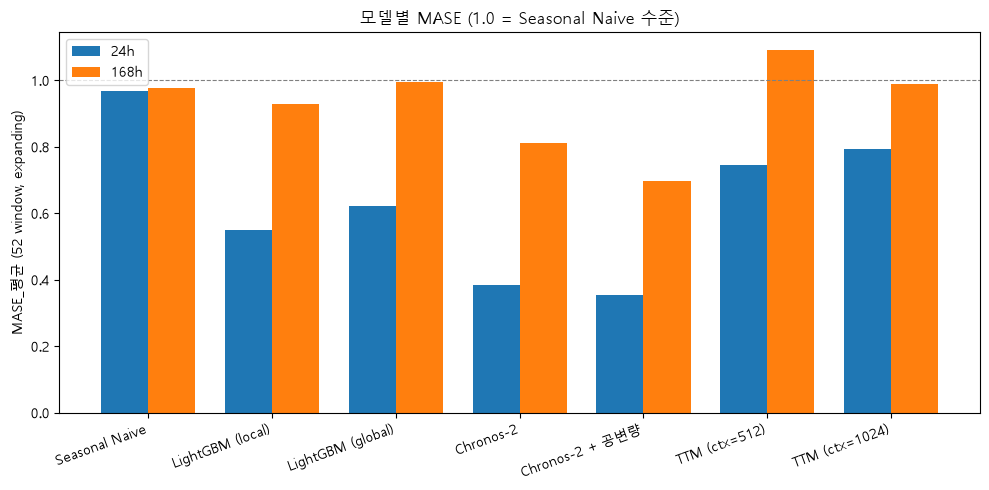

In [4]:
rows = []
for h in (24, 168):
    for t in ("TTM (ctx=512)", "TTM (ctx=1024)"):
        c, m, nv = mase[("Chronos-2", h)], mase[(t, h)], mase[("Seasonal Naive", h)]
        rows.append({"horizon": h, "TTM": t, "TTM MASE": m.mean(), "Chronos-2 MASE": c.mean(),
                     "TTM/Chronos-2": m.mean() / c.mean(), "Naive 대비 TTM 개선(%)": (nv.mean() - m.mean()) / nv.mean() * 100,
                     "Chronos-2 승 건물": int((c < m).sum()), "TTM 승 건물": int((m < c).sum())})
ttm_vs_chronos = pd.DataFrame(rows)
ttm_vs_chronos.to_csv(OUT / "ttm_vs_chronos.csv", index=False, encoding="utf-8")
print(ttm_vs_chronos.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(summary))
w = 0.38
ax.bar(x - w / 2, summary["MASE(24h)"], w, label="24h")
ax.bar(x + w / 2, summary["MASE(168h)"], w, label="168h")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(summary.index, rotation=20, ha="right")
ax.set_ylabel("MASE_평균 (52 window, expanding)")
ax.set_title("모델별 MASE (1.0 = Seasonal Naive 수준)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "mase_by_model.png", dpi=110)
plt.show()

## 과제 6-2. 전체 벤치마크

In [5]:
def measure(model, threads, series=1, repeats=11, train=False, tag=0):
    path = RAW / f"{model}_t{threads}_s{series}_{'train' if train else 'infer'}_{tag}.json"
    if not path.exists():
        cmd = [sys.executable, str(ROOT / "src" / "measure_inference.py"), "--model", model, "--threads", str(threads),
               "--repeats", str(repeats), "--series", str(series), "--out", str(path)] + (["--train"] if train else [])
        subprocess.run(cmd, check=True, capture_output=True, cwd=ROOT)
    return json.loads(path.read_text(encoding="utf-8"))


MEAS = ["naive", "lgb_local_direct", "lgb_local_recursive", "lgb_global_direct", "lgb_global_recursive",
        "chronos", "chronos_cov", "ttm512", "ttm1024"]
infer4 = {m: [measure(m, 4, tag=i) for i in range(3)] for m in MEAS}
print("4스레드 단일 계열 측정 완료")

4스레드 단일 계열 측정 완료


In [6]:
infer2 = {m: [measure(m, 2, tag=i) for i in range(2)] for m in MEAS}
train_t = {m: measure(m, 4, train=True) for m in ["lgb_local_direct", "lgb_local_recursive",
                                                   "lgb_global_direct", "lgb_global_recursive"]}
print("2스레드 단일 계열 + 학습 시간 측정 완료")

2스레드 단일 계열 + 학습 시간 측정 완료


In [7]:
big = {m: measure(m, 2, series=500, repeats=2) for m in ["naive", "lgb_local_direct", "ttm512", "ttm1024", "chronos"]}
print("500계열 × 2스레드 측정 완료")

500계열 × 2스레드 측정 완료


In [8]:
def agg(runs):
    return {"ms": float(np.median([r["median_ms"] for r in runs])),
            "ms_min": min(r["min_ms"] for r in runs), "ms_max": max(r["max_ms"] for r in runs),
            "base_mb": float(np.median([r["baseline_mb"] for r in runs])),
            "peak_mb": float(np.median([r["peak_mb"] for r in runs]))}


ROWS = {  # 표 행 이름 -> (대표 측정 모델, recursive 측정 모델, 학습 시간 모델)
    "Seasonal Naive": ("naive", None, None),
    "LightGBM (local)": ("lgb_local_direct", "lgb_local_recursive", "lgb_local_direct"),
    "LightGBM (global)": ("lgb_global_direct", "lgb_global_recursive", "lgb_global_direct"),
    "Chronos-2": ("chronos", None, None),
    "Chronos-2 + 공변량": ("chronos_cov", None, None),
    "TTM (ctx=512)": ("ttm512", None, None),
    "TTM (ctx=1024)": ("ttm1024", None, None),
}
bench = []
for name, (main, rec, trn) in ROWS.items():
    a4, a2 = agg(infer4[main]), agg(infer2[main])
    bench.append({
        "모델": name, "MASE(24h)": summary.loc[name, "MASE(24h)"], "MASE(168h)": summary.loc[name, "MASE(168h)"],
        "추론 ms/계열(4스레드)": a4["ms"], "추론 최소": a4["ms_min"], "추론 최대": a4["ms_max"],
        "recursive ms/계열": agg(infer4[rec])["ms"] if rec else np.nan,
        "추론 ms/계열(2스레드)": a2["ms"],
        "학습 시간(s)": train_t[trn]["train_s"] if trn else np.nan,
        "recursive 학습(s)": train_t[rec.replace("recursive", "recursive")]["train_s"] if rec else np.nan,
        "RAM baseline(MB)": a4["base_mb"], "RAM 추론 피크(MB)": a4["peak_mb"],
    })
bench = pd.DataFrame(bench)
bench.to_csv(OUT / "benchmark_table.csv", index=False, encoding="utf-8")
print(bench.round(3).to_string(index=False))
print("\n측정 방식: LightGBM은 direct(24행 배치 1회 호출)와 recursive(24스텝 순차)를 둘 다 기록, Chronos-2·TTM은 단일 호출 / "
      "스레드 4(별도로 2스레드), 프로세스당 11회 호출(첫 호출 제외 10회 중앙값) × 독립 프로세스 3회의 중앙값")

               모델  MASE(24h)  MASE(168h)  추론 ms/계열(4스레드)   추론 최소   추론 최대  recursive ms/계열  추론 ms/계열(2스레드)  학습 시간(s)  recursive 학습(s)  RAM baseline(MB)  RAM 추론 피크(MB)
   Seasonal Naive      0.967       0.977           0.072   0.044   0.218              NaN           0.051       NaN              NaN           445.004        445.102
 LightGBM (local)      0.550       0.930          17.810  16.831  22.619          479.936          15.110     4.293            4.303           445.203        451.734
LightGBM (global)      0.621       0.996          25.284  21.453  33.098          545.214          20.566     5.970            6.131           444.824        451.656
        Chronos-2      0.384       0.810         154.661 138.941 166.231              NaN         147.461       NaN              NaN           445.711        916.359
  Chronos-2 + 공변량      0.355       0.697         294.083 267.085 388.917              NaN         306.868       NaN              NaN           447.203        958.609
    

## 과제 6-3. 6축 배포 판단표 · 시나리오

In [9]:
COLD = {  # 시나리오 B 콜드스타트: 직전 2주(336h)만 보유한 상태로 52 window 백테스트 (train_mode=sliding, sliding_train_len=336)
    "Seasonal Naive": lambda h: bm.make_naive_fns(),
    "LightGBM (local)": lambda h: bm.make_local_fns(h),
    "LightGBM (global)": lambda h: bm.make_global_fns(h),
    "Chronos-2": lambda h: bm.make_chronos_fns(1024),
    "Chronos-2 + 공변량": lambda h: bm.make_chronos_fns(1024, True, weather, building_site),
    "TTM (ctx=512)": lambda h: bm.make_ttm_fns(512),
    "TTM (ctx=1024)": lambda h: bm.make_ttm_fns(1024),
    "TTM (ctx=512, 주기패딩)": lambda h: bm.make_ttm_fns(512, "tile"),
    "TTM (ctx=1024, 주기패딩)": lambda h: bm.make_ttm_fns(1024, "tile"),
}
cold = {}
for name, mk in COLD.items():
    for h in (24, 168):
        cold[(name, h)] = cached_mase("coldstart " + name, h,
                                      lambda mk=mk, h=h: run_backtest(mk(h), h, train_mode="sliding", sliding_train_len=336))
cold_df = pd.DataFrame({f"MASE({h}h)": {n: cold[(n, h)].mean() for n in COLD} for h in (24, 168)})
cold_df["MASE(24h) 전체이력"] = [summary.loc[n.replace(", 주기패딩", ""), "MASE(24h)"] for n in cold_df.index]
cold_df.to_csv(OUT / "scenario_B_coldstart.csv", encoding="utf-8")
print(cold_df.round(4).to_string())

INFO:p-32964:t-12932:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2


INFO:p-32964:t-12932:get_model.py:get_model:Model path type is 2


INFO:p-32964:t-12932:get_model.py:get_model:Attempting model load from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


INFO:p-32964:t-12932:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


INFO:p-32964:t-12932:get_model.py:get_model:[TTM] context_length = 512, prediction_length = 48


...

INFO:p-32964:t-12932:get_model.py:get_model:Model path type is 2


INFO:p-32964:t-12932:get_model.py:get_model:Attempting model load from ibm-granite/granite-timeseries-ttm-r2, revision = 1024-192-r2.


INFO:p-32964:t-12932:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1024-192-r2.


INFO:p-32964:t-12932:get_model.py:get_model:[TTM] context_length = 1024, prediction_length = 192


                      MASE(24h)  MASE(168h)  MASE(24h) 전체이력
Seasonal Naive           0.9673      0.9767          0.9673
LightGBM (local)         0.6045      0.9957          0.5501
LightGBM (global)        0.7212      1.2031          0.6211
Chronos-2                0.4174      0.8619          0.3837
Chronos-2 + 공변량          0.3917      0.7760          0.3545
TTM (ctx=512)            1.5096      1.4241          0.7447
TTM (ctx=1024)           2.7289      1.4292          0.7933
TTM (ctx=512, 주기패딩)      0.7528      1.0830          0.7447
TTM (ctx=1024, 주기패딩)     0.8214      1.0014          0.7933


In [10]:
CYCLE_C, RAM_C = 60.0, 4096.0
KEY = {"Seasonal Naive": "naive", "LightGBM (local)": "lgb_local_direct", "LightGBM (global)": "lgb_global_direct",
       "Chronos-2": "chronos", "Chronos-2 + 공변량": "chronos_cov", "TTM (ctx=512)": "ttm512", "TTM (ctx=1024)": "ttm1024"}
rows_c = []
for name, key in KEY.items():
    if key in big:
        t500 = big[key]["times_ms"][-1] / 1000
        ram = big[key]["peak_mb"]
        src = "실측(500계열)"
    else:
        t500 = agg(infer2[key])["ms"] * 500 / 1000
        ram = agg(infer2[key])["peak_mb"]
        src = "단일계열×500 외삽(상한)"
    rows_c.append({"모델": name, "500계열 소요(s)": t500, "피크 RAM(MB)": ram, "산출": src,
                   "1분 주기 충족": t500 <= CYCLE_C, "4GB 충족": ram <= RAM_C, "MASE(24h)": summary.loc[name, "MASE(24h)"]})
for rec_name, key in [("LightGBM (local) recursive", "lgb_local_recursive"), ("LightGBM (global) recursive", "lgb_global_recursive")]:
    t500 = agg(infer2[key])["ms"] * 500 / 1000
    rows_c.append({"모델": rec_name, "500계열 소요(s)": t500, "피크 RAM(MB)": agg(infer2[key])["peak_mb"],
                   "산출": "단일계열×500 외삽(상한)", "1분 주기 충족": t500 <= CYCLE_C,
                   "4GB 충족": agg(infer2[key])["peak_mb"] <= RAM_C,
                   "MASE(24h)": summary.loc[rec_name.replace(" recursive", ""), "MASE(24h)"]})
scen_c = pd.DataFrame(rows_c)
scen_c.to_csv(OUT / "scenario_C_throughput.csv", index=False, encoding="utf-8")
print(scen_c.round(2).to_string(index=False))
print("\nChronos-2 500계열 호출별 소요(s):", [round(t / 1000, 1) for t in big["chronos"]["times_ms"]],
      "| 단일계열 2스레드 ms/계열:", round(agg(infer2["chronos"])["ms"], 1), "→ 배치 ms/계열:", round(big["chronos"]["per_series_ms"], 1))

                         모델  500계열 소요(s)  피크 RAM(MB)              산출  1분 주기 충족  4GB 충족  MASE(24h)
             Seasonal Naive         0.00      512.05       실측(500계열)      True    True       0.97
           LightGBM (local)         8.64      668.96       실측(500계열)      True    True       0.55
          LightGBM (global)        10.28      449.79 단일계열×500 외삽(상한)      True    True       0.62
                  Chronos-2        60.26     2102.48       실측(500계열)     False    True       0.38
            Chronos-2 + 공변량       153.43      954.13 단일계열×500 외삽(상한)     False    True       0.35
              TTM (ctx=512)         0.26      585.88       실측(500계열)      True    True       0.74
             TTM (ctx=1024)         0.60      621.11       실측(500계열)      True    True       0.79
 LightGBM (local) recursive       190.38      455.89 단일계열×500 외삽(상한)     False    True       0.55
LightGBM (global) recursive       209.76      458.09 단일계열×500 외삽(상한)     False    True       0.62

Chronos-2 500계열 호출별

In [11]:
CYCLE_A = 3600.0
rows_a = []
for name, key in KEY.items():
    ms = agg(infer4[key])["ms"]
    cyc = ms * 50 / 1000
    trn = train_t[key]["train_s"] * 50 / 17 if key in train_t else 0.0
    rows_a.append({"모델": name, "50계열 1회 추론(s)": cyc, "재학습 시간(50계열 환산, s)": trn,
                   "1시간 주기 충족": cyc <= CYCLE_A, "MASE(24h)": summary.loc[name, "MASE(24h)"],
                   "MASE(168h)": summary.loc[name, "MASE(168h)"]})
scen_a = pd.DataFrame(rows_a)
scen_a.to_csv(OUT / "scenario_A.csv", index=False, encoding="utf-8")
print(scen_a.round(3).to_string(index=False))

               모델  50계열 1회 추론(s)  재학습 시간(50계열 환산, s)  1시간 주기 충족  MASE(24h)  MASE(168h)
   Seasonal Naive          0.004               0.000       True      0.967       0.977
 LightGBM (local)          0.891              12.627       True      0.550       0.930
LightGBM (global)          1.264              17.558       True      0.621       0.996
        Chronos-2          7.733               0.000       True      0.384       0.810
  Chronos-2 + 공변량         14.704               0.000       True      0.355       0.697
    TTM (ctx=512)          0.220               0.000       True      0.745       1.090
   TTM (ctx=1024)          0.250               0.000       True      0.793       0.990


In [12]:
base24 = summary.loc["Seasonal Naive", "MASE(24h)"]
EXPL = {"Seasonal Naive": "규칙 자체가 설명(1주 전 같은 시각 값)", "LightGBM (local)": "SHAP으로 피처 기여도 설명 가능",
        "LightGBM (global)": "SHAP으로 피처 기여도 설명 가능", "Chronos-2": "블랙박스(분위수 예측만 제공)",
        "Chronos-2 + 공변량": "블랙박스(공변량 기여 분해 불가)", "TTM (ctx=512)": "블랙박스", "TTM (ctx=1024)": "블랙박스"}
FACT = {"Seasonal Naive": "1주 이력이면 즉시 가동", "LightGBM (local)": "2주치로 재학습해야 가동",
        "LightGBM (global)": "2주치로 재학습해야 가동", "Chronos-2": "학습 없이 즉시 가동",
        "Chronos-2 + 공변량": "학습 없이 즉시 가동", "TTM (ctx=512)": "학습 없이 가동, 컨텍스트 미만이면 패딩 필요",
        "TTM (ctx=1024)": "학습 없이 가동, 컨텍스트 미만이면 패딩 필요"}


def cold_note(n):
    c, f = cold_df.loc[n, "MASE(24h)"], cold_df.loc[n, "MASE(24h) 전체이력"]
    note = f"2주 이력 MASE24h {c:.3f}(전체이력 대비 {(c - f) / f * 100:+.0f}%) · {FACT[n]}"
    if n.startswith("TTM"):
        note += f" · 기본 제로패딩 값이며 주기 패딩이면 {cold_df.loc[n.replace(')', ', 주기패딩)'), 'MASE(24h)']:.3f}"
    return note


six = []
for _, r in bench.iterrows():
    n = r["모델"]
    imp = (base24 - r["MASE(24h)"]) / base24 * 100
    ops = (f"학습 {r['학습 시간(s)']:.1f}s(17계열), 재학습 필요·계열 수에 비례" if not np.isnan(r["학습 시간(s)"])
           else ("운영 비용 없음" if n == "Seasonal Naive" else "학습·재학습 불필요, 계열 N개면 추론 ≈ N배"))
    six.append({"모델": n,
                "정확도": f"MASE 24h {r['MASE(24h)']:.3f}(Naive 대비 {imp:+.0f}%), 168h {r['MASE(168h)']:.3f}",
                "지연": f"{r['추론 ms/계열(4스레드)']:.1f}ms/계열" + (f", recursive {r['recursive ms/계열']:.0f}ms" if not np.isnan(r["recursive ms/계열"]) else ""),
                "자원": f"RAM 피크 {r['RAM 추론 피크(MB)']:.0f}MB, GPU 불필요",
                "운영": ops, "설명": EXPL[n],
                "콜드스타트": cold_note(n)})
six = pd.DataFrame(six)
six.to_csv(OUT / "six_axis_table.csv", index=False, encoding="utf-8")
print(six.to_string(index=False))

               모델                                       정확도                         지연                    자원                             운영                      설명                                                                                      콜드스타트
   Seasonal Naive  MASE 24h 0.967(Naive 대비 +0%), 168h 0.977                   0.1ms/계열 RAM 피크 445MB, GPU 불필요                       운영 비용 없음 규칙 자체가 설명(1주 전 같은 시각 값)                                           2주 이력 MASE24h 0.967(전체이력 대비 +0%) · 1주 이력이면 즉시 가동
 LightGBM (local) MASE 24h 0.550(Naive 대비 +43%), 168h 0.930 17.8ms/계열, recursive 480ms RAM 피크 452MB, GPU 불필요 학습 4.3s(17계열), 재학습 필요·계열 수에 비례     SHAP으로 피처 기여도 설명 가능                                          2주 이력 MASE24h 0.604(전체이력 대비 +10%) · 2주치로 재학습해야 가동
LightGBM (global) MASE 24h 0.621(Naive 대비 +36%), 168h 0.996 25.3ms/계열, recursive 545ms RAM 피크 452MB, GPU 불필요 학습 6.0s(17계열), 재학습 필요·계열 수에 비례     SHAP으로 피처 기여도 설명 가능                                          2주 이력 MASE24h 0.721(전체이력 대비 +1

                      시나리오               선택                                                                                                     근거
A (이력 2년, GPU 없는 온프렘, 50개)  Chronos-2 + 공변량                                               가정: 1시간 주기. 50계열 1회 추론 15s로 충족한 모델 중 MASE(24h) 0.355(최저)
          B (신규 준공, 이력 2주)  Chronos-2 + 공변량                            2주 이력만으로 MASE(24h) 0.392(최저), 같은 조건 LightGBM(global) 0.721 / TTM(512) 1.510
 C (RAM 4GB·2코어, 500계열·1분) LightGBM (local) 500계열 8.6s·RAM 669MB로 충족한 모델 중 MASE(24h) 0.550(최저). Chronos-2는 RAM 2102MB로 4GB엔 올라가지만 500계열 60s로 1분 초과


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


...

INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


INFO:p-32964:t-12932:_mathtext.py:_get_glyph:Substituting symbol − from STIXGeneral


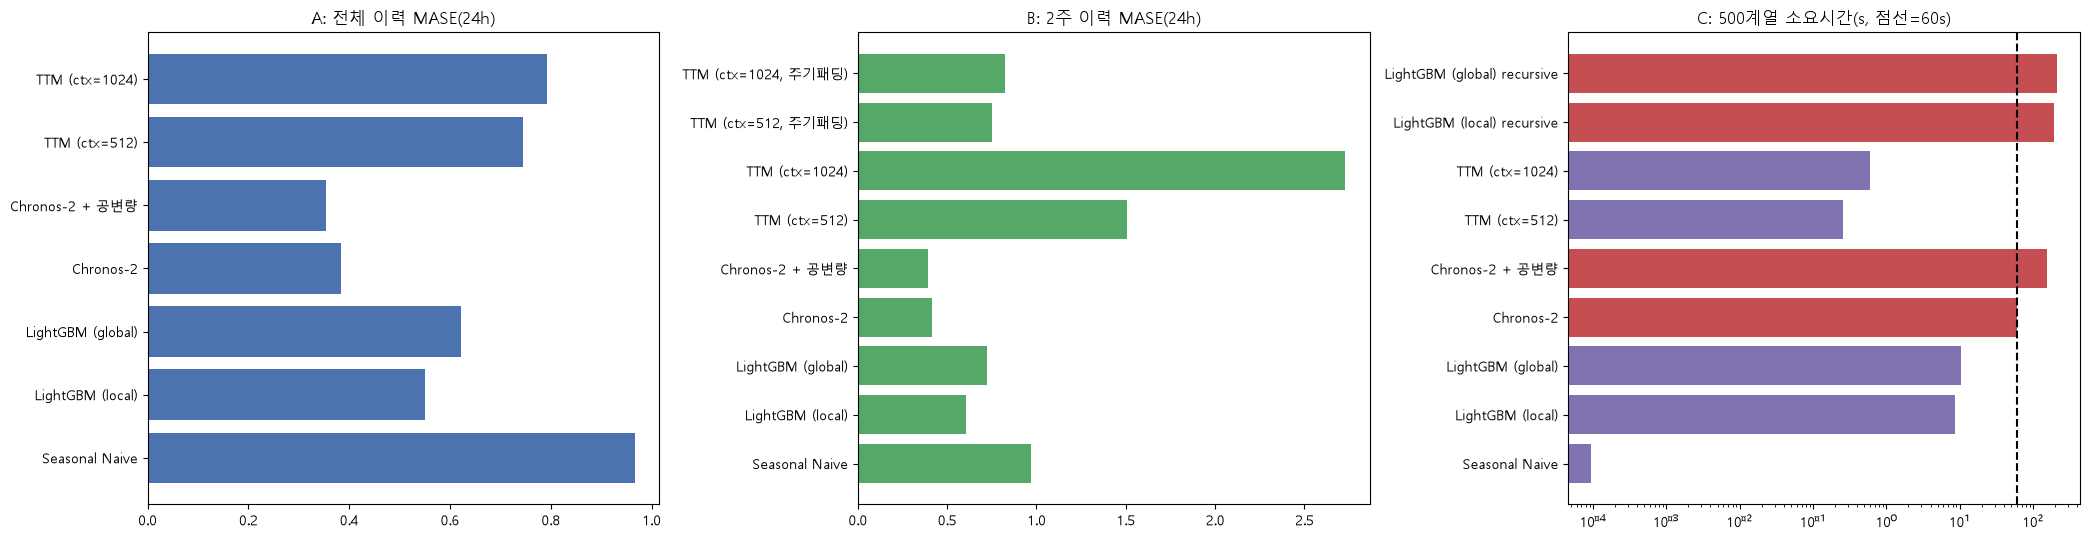

In [13]:
ok_c = scen_c[scen_c["1분 주기 충족"] & scen_c["4GB 충족"]]
pick_c = ok_c.sort_values("MASE(24h)").iloc[0]
pick_a = scen_a[scen_a["1시간 주기 충족"]].sort_values("MASE(24h)").iloc[0]
pick_b = cold_df["MASE(24h)"].sort_values().index[0]
ch = scen_c.set_index("모델").loc["Chronos-2"]
choices = pd.DataFrame([
    {"시나리오": "A (이력 2년, GPU 없는 온프렘, 50개)", "선택": pick_a["모델"],
     "근거": f"가정: 1시간 주기. 50계열 1회 추론 {pick_a['50계열 1회 추론(s)']:.0f}s로 충족한 모델 중 MASE(24h) {pick_a['MASE(24h)']:.3f}(최저)"},
    {"시나리오": "B (신규 준공, 이력 2주)", "선택": pick_b,
     "근거": f"2주 이력만으로 MASE(24h) {cold_df.loc[pick_b, 'MASE(24h)']:.3f}(최저), 같은 조건 LightGBM(global) {cold_df.loc['LightGBM (global)', 'MASE(24h)']:.3f} / TTM(512) {cold_df.loc['TTM (ctx=512)', 'MASE(24h)']:.3f}"},
    {"시나리오": "C (RAM 4GB·2코어, 500계열·1분)", "선택": pick_c["모델"],
     "근거": f"500계열 {pick_c['500계열 소요(s)']:.1f}s·RAM {pick_c['피크 RAM(MB)']:.0f}MB로 충족한 모델 중 MASE(24h) {pick_c['MASE(24h)']:.3f}(최저). Chronos-2는 RAM {ch['피크 RAM(MB)']:.0f}MB로 4GB엔 올라가지만 500계열 {ch['500계열 소요(s)']:.0f}s로 1분 초과"},
])
choices.to_csv(OUT / "scenario_choices.csv", index=False, encoding="utf-8")
print(choices.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
order_a = scen_a.set_index("모델")["MASE(24h)"]
axes[0].barh(order_a.index, order_a.values, color="#4C72B0")
axes[0].set_title("A: 전체 이력 MASE(24h)")
axes[1].barh(cold_df.index, cold_df["MASE(24h)"].values, color="#55A868")
axes[1].set_title("B: 2주 이력 MASE(24h)")
cc = scen_c.set_index("모델")["500계열 소요(s)"]
axes[2].barh(cc.index, cc.values, color=["#C44E52" if v > CYCLE_C else "#8172B2" for v in cc.values])
axes[2].axvline(CYCLE_C, color="black", linestyle="--")
axes[2].set_xscale("log")
axes[2].set_title("C: 500계열 소요시간(s, 점선=60s)")
plt.tight_layout()
plt.savefig(OUT / "scenario_summary.png", dpi=110)
plt.show()